In [1]:
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.datasets import mnist
from skimage.transform import rotate, AffineTransform, warp
from scipy.ndimage import shift, zoom
from itertools import product

rng = np.random.default_rng(42)

(train_X, train_y), (test_X, test_y) = mnist.load_data()

train_X = train_X / 255.0
test_X = test_X / 255.0

# Use a small subset to reduce computation time
train_X = train_X[::1200].copy()
train_y = train_y[::1200].copy()

print("Training samples:", len(train_X))
print("Testing samples:", len(test_X))

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Training samples: 50
Testing samples: 10000


In [2]:
def NN(train_X, train_y, test_X):
    train_X = train_X.reshape(len(train_X), -1)
    test_X = test_X.reshape(len(test_X), -1)

    predictions = []

    for x in test_X:
        distances = np.sum((train_X - x) ** 2, axis=1)
        predictions.append(train_y[np.argmin(distances)])

    return np.array(predictions)


def Accuracy(actual, predicted):
    return np.mean(actual == predicted)

In [3]:
baseline = Accuracy(test_y, NN(train_X, train_y, test_X)) * 100

print("Baseline accuracy:", round(baseline, 2), "%")

Baseline accuracy: 64.72 %


In [4]:
def augRotate(X, angle):
    return np.array([rotate(x, rng.uniform(-angle/2, angle/2))
                     for x in X])

def shear(image, amount):
    return warp(image, AffineTransform(shear=amount))

def augShear(X, constraint):
    return np.array([shear(x, rng.uniform(-constraint/2, constraint/2))
                     for x in X])

def augRotateShear(X, angle, amount):
    return np.array([
        rotate(shear(x, rng.uniform(-amount/2, amount/2)),
               rng.uniform(-angle/2, angle/2))
        for x in X
    ])

Angle: 0 Accuracy: 64.72 %
Angle: 10 Accuracy: 67.2 %
Angle: 20 Accuracy: 67.08 %
Angle: 30 Accuracy: 68.52 %
Angle: 40 Accuracy: 68.08 %
Angle: 50 Accuracy: 67.79 %
Angle: 60 Accuracy: 67.28 %
Angle: 70 Accuracy: 66.76 %
Angle: 80 Accuracy: 65.04 %
Angle: 90 Accuracy: 64.67 %
Best angle: 30
Best accuracy: 68.52 %
Improvement: 3.8 percentage points


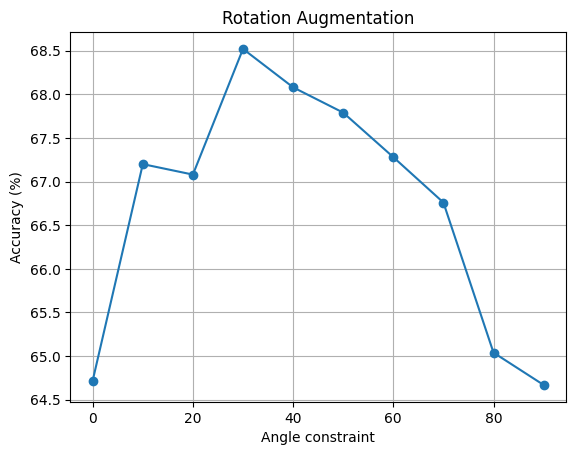

In [5]:
angles = [0, 10, 20, 30, 40, 50, 60, 70, 80, 90]
rotation_results = []

for angle in angles:
    X_aug = [train_X]
    y_aug = [train_y]

    for _ in range(5):
        X_aug.append(augRotate(train_X, angle))
        y_aug.append(train_y)

    X_all = np.concatenate(X_aug)
    y_all = np.concatenate(y_aug)

    acc = Accuracy(test_y, NN(X_all, y_all, test_X)) * 100
    rotation_results.append(acc)
    print("Angle:", angle, "Accuracy:", round(acc, 2), "%")

best_angle = angles[np.argmax(rotation_results)]
best_rotation = max(rotation_results)

print("Best angle:", best_angle)
print("Best accuracy:", round(best_rotation, 2), "%")
print("Improvement:", round(best_rotation - baseline, 2), "percentage points")

plt.plot(angles, rotation_results, marker="o")
plt.xlabel("Angle constraint")
plt.ylabel("Accuracy (%)")
plt.title("Rotation Augmentation")
plt.grid()
plt.show()

Shear: 0 Accuracy: 64.72 %
Shear: 0.2 Accuracy: 66.56 %
Shear: 0.4 Accuracy: 64.4 %
Shear: 0.6 Accuracy: 63.25 %
Shear: 0.8 Accuracy: 63.89 %
Shear: 1.0 Accuracy: 63.45 %
Shear: 1.2 Accuracy: 62.8 %
Shear: 1.4 Accuracy: 61.87 %
Shear: 1.6 Accuracy: 64.61 %
Shear: 1.8 Accuracy: 63.86 %
Shear: 2.0 Accuracy: 64.4 %
Best shear: 0.2
Best accuracy: 66.56 %


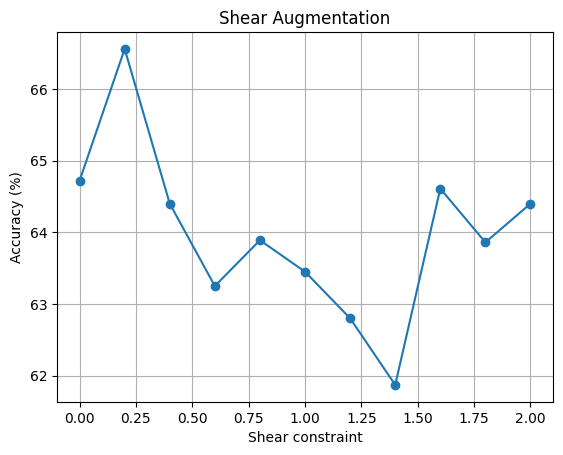

In [6]:
shears = [0, 0.2, 0.4, 0.6, 0.8, 1.0, 1.2, 1.4, 1.6, 1.8, 2.0]
shear_results = []

for amount in shears:
    X_aug = [train_X]
    y_aug = [train_y]

    for _ in range(5):
        X_aug.append(augShear(train_X, amount))
        y_aug.append(train_y)

    X_all = np.concatenate(X_aug)
    y_all = np.concatenate(y_aug)

    acc = Accuracy(test_y, NN(X_all, y_all, test_X)) * 100
    shear_results.append(acc)
    print("Shear:", amount, "Accuracy:", round(acc, 2), "%")

best_shear = shears[np.argmax(shear_results)]

print("Best shear:", best_shear)
print("Best accuracy:", round(max(shear_results), 2), "%")

plt.plot(shears, shear_results, marker="o")
plt.xlabel("Shear constraint")
plt.ylabel("Accuracy (%)")
plt.title("Shear Augmentation")
plt.grid()
plt.show()

Augmentations: 1 Accuracy: 63.56 %
Augmentations: 2 Accuracy: 66.37 %
Augmentations: 3 Accuracy: 67.79 %
Augmentations: 5 Accuracy: 68.74 %
Augmentations: 8 Accuracy: 67.73 %


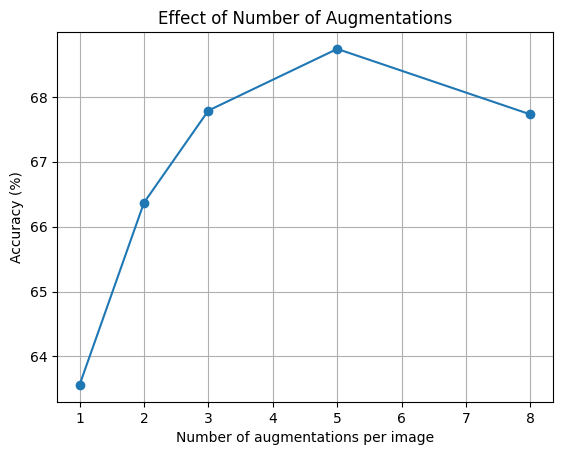

In [7]:
counts = [1, 2, 3, 5, 8]
count_results = []

for n in counts:
    X_aug = [train_X]
    y_aug = [train_y]

    for _ in range(n):
        X_aug.append(augRotate(train_X, best_angle))
        y_aug.append(train_y)

    X_all = np.concatenate(X_aug)
    y_all = np.concatenate(y_aug)

    acc = Accuracy(test_y, NN(X_all, y_all, test_X)) * 100
    count_results.append(acc)
    print("Augmentations:", n, "Accuracy:", round(acc, 2), "%")

plt.plot(counts, count_results, marker="o")
plt.xlabel("Number of augmentations per image")
plt.ylabel("Accuracy (%)")
plt.title("Effect of Number of Augmentations")
plt.grid()
plt.show()

In [8]:
def augShift(X):
    return np.array([shift(x, (2, 2), cval=0) for x in X])

def augZoom(X):
    result = []

    for x in X:
        small = zoom(x, 0.9)
        output = np.zeros_like(x)
        start = (28 - small.shape[0]) // 2
        output[start:start+small.shape[0],
               start:start+small.shape[1]] = small
        result.append(output)

    return np.array(result)


for name, function in [("Shift", augShift), ("Zoom", augZoom)]:
    X_all = np.concatenate([train_X, function(train_X)])
    y_all = np.concatenate([train_y, train_y])

    acc = Accuracy(test_y, NN(X_all, y_all, test_X)) * 100
    print(name, "accuracy:", round(acc, 2), "%")

Shift accuracy: 61.14 %
Zoom accuracy: 64.68 %


In [9]:
def augShift(X):
    return np.array([shift(x, (2, 2), cval=0) for x in X])

def augZoom(X):
    result = []

    for x in X:
        small = zoom(x, 0.9)
        output = np.zeros_like(x)
        start = (28 - small.shape[0]) // 2
        output[start:start+small.shape[0],
               start:start+small.shape[1]] = small
        result.append(output)

    return np.array(result)


for name, function in [("Shift", augShift), ("Zoom", augZoom)]:
    X_all = np.concatenate([train_X, function(train_X)])
    y_all = np.concatenate([train_y, train_y])

    acc = Accuracy(test_y, NN(X_all, y_all, test_X)) * 100
    print(name, "accuracy:", round(acc, 2), "%")

Shift accuracy: 61.14 %
Zoom accuracy: 64.68 %


Angle: 0 Shear: 0 Accuracy: 64.72 %
Angle: 0 Shear: 0.2 Accuracy: 65.24 %
Angle: 0 Shear: 0.4 Accuracy: 64.98 %
Angle: 0 Shear: 0.6 Accuracy: 64.17 %
Angle: 10 Shear: 0 Accuracy: 67.36 %
Angle: 10 Shear: 0.2 Accuracy: 67.66 %
Angle: 10 Shear: 0.4 Accuracy: 66.07 %
Angle: 10 Shear: 0.6 Accuracy: 63.43 %
Angle: 20 Shear: 0 Accuracy: 67.99 %
Angle: 20 Shear: 0.2 Accuracy: 68.17 %
Angle: 20 Shear: 0.4 Accuracy: 65.18 %
Angle: 20 Shear: 0.6 Accuracy: 65.31 %
Angle: 30 Shear: 0 Accuracy: 68.63 %
Angle: 30 Shear: 0.2 Accuracy: 68.85 %
Angle: 30 Shear: 0.4 Accuracy: 63.45 %
Angle: 30 Shear: 0.6 Accuracy: 65.47 %

Best angle: 30
Best shear: 0.2
Highest accuracy: 68.85 %


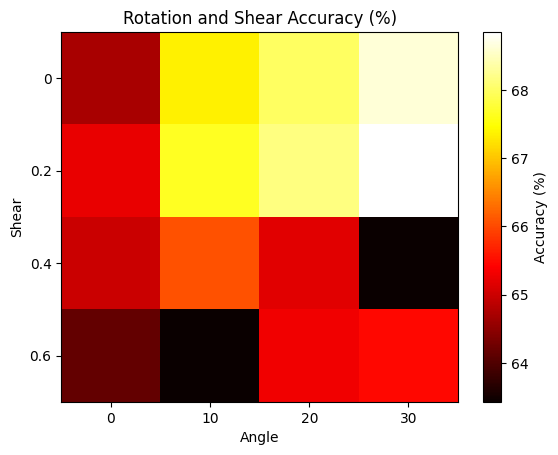

In [10]:
angles = [0, 10, 20, 30]
shears = [0, 0.2, 0.4, 0.6]
combined_results = []

for angle, amount in product(angles, shears):
    X_aug = [train_X]
    y_aug = [train_y]

    for _ in range(5):
        X_aug.append(augRotateShear(train_X, angle, amount))
        y_aug.append(train_y)

    X_all = np.concatenate(X_aug)
    y_all = np.concatenate(y_aug)

    acc = Accuracy(test_y, NN(X_all, y_all, test_X)) * 100
    combined_results.append((angle, amount, acc))

    print("Angle:", angle, "Shear:", amount,
          "Accuracy:", round(acc, 2), "%")

best_combo = max(combined_results, key=lambda x: x[2])
print("\nBest angle:", best_combo[0])
print("Best shear:", best_combo[1])
print("Highest accuracy:", round(best_combo[2], 2), "%")

matrix = np.array([
    [next(r[2] for r in combined_results
          if r[0] == a and r[1] == s) for a in angles]
    for s in shears
])

plt.imshow(matrix, cmap="hot", aspect="auto")
plt.xticks(range(len(angles)), angles)
plt.yticks(range(len(shears)), shears)
plt.xlabel("Angle")
plt.ylabel("Shear")
plt.title("Rotation and Shear Accuracy (%)")
plt.colorbar(label="Accuracy (%)")
plt.show()

In [11]:
(train_full, train_labels), (test_full, test_labels) = mnist.load_data()

train_full = train_full / 255.0
test_full = test_full / 255.0

X, y = [], []

for digit in range(10):
    indices = np.where(train_labels == digit)[0][:50]
    X.extend(train_full[indices])
    y.extend(train_labels[indices])

X = np.array(X)
y = np.array(y)

print("Training samples:", len(X))

pred = NN(X, y, test_full)
print("Accuracy without augmentation:",
      round(Accuracy(test_labels, pred) * 100, 2), "%")

X_aug = [X]
y_aug = [y]

for _ in range(5):
    X_aug.append(augRotate(X, best_angle))
    y_aug.append(y)

X_combined = np.concatenate(X_aug)
y_combined = np.concatenate(y_aug)

pred_aug = NN(X_combined, y_combined, test_full)

print("Accuracy with augmentation:",
      round(Accuracy(test_labels, pred_aug) * 100, 2), "%")

Training samples: 500
Accuracy without augmentation: 83.54 %
Accuracy with augmentation: 87.51 %
